KNN Regressor

In [46]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsRegressor

df = pd.read_csv("/Applications/MAMP/htdocs/local/kodingakademi/Python/bootcamp data analis/pertemuan/ML/death_clean.csv")
df.head()

,Cause,Type,Year,Data Redundancy,Total Deaths,Source,Page at Source,Source URL
0,Abrasi Air Laut,Bencana Alam,2012,1,0,Profil Kesehatan Indonesia Tahun 2012,Lampiran 3.38,https://pusdatin.kemkes.go.id/download.php?fil...
1,AIDS,Bencana Non Alam dan Penyakit,2000,1,47,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
2,AIDS,Bencana Non Alam dan Penyakit,2001,1,99,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
3,AIDS,Bencana Non Alam dan Penyakit,2002,1,100,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
4,AIDS,Bencana Non Alam dan Penyakit,2003,1,261,Profil Kesehatan Indonesia Tahun 2010,115,https://pusdatin.kemkes.go.id/download.php?fil...


In [47]:
x = df[["Cause", "Type"]]
y = df[["Total Deaths"]]

x_encode = pd.get_dummies(x, columns=["Cause", "Type"])

scale = MinMaxScaler()
y_norm = scale.fit_transform(y).ravel()

x_train, x_test, y_train, y_test = train_test_split(x_encode, y_norm, test_size=0.3, random_state=42)

print(f"x_train = {len(x_train)}, x_test = {len(x_test)}")
print(f"y_train = {len(y_train)}, y_test = {len(y_test)}")

x_train = 385, x_test = 165
y_train = 385, y_test = 165


In [48]:
knn = KNeighborsRegressor(n_neighbors=3)
knn.fit(x_train, y_train)

y_pred = knn.predict(x_test)
y_pred

array([2.75668073e-01, 1.05016409e-01, 5.57899672e-02, 7.50117206e-02,
       1.10173465e-01, 1.10173465e-01, 1.05016409e-01, 4.17252696e-02,
       1.17205813e-02, 5.20393812e-02, 1.87529301e-03, 5.13830286e-01,
       1.05016409e-01, 1.57524613e-01, 3.16924519e-01, 1.05016409e-01,
       4.17252696e-02, 5.13830286e-01, 4.54758556e-02, 6.00093765e-02,
       2.95358650e-02, 1.33614627e-01, 1.41584623e-01, 4.21940928e-03,
       1.05016409e-01, 3.84435068e-02, 1.87529301e-03, 4.50070323e-02,
       6.09470230e-02, 6.09470230e-02, 5.62587904e-03, 5.15705579e-02,
       4.17252696e-02, 1.05016409e-01, 4.73511486e-02, 1.05016409e-01,
       5.13830286e-01, 1.33614627e-01, 4.87576184e-02, 4.87576184e-02,
       2.75668073e-01, 1.87529301e-03, 4.59446789e-02, 1.05016409e-01,
       4.73511486e-02, 1.60806376e-01, 1.10173465e-01, 6.09470230e-02,
       2.85982185e-02, 6.09470230e-02, 2.95358650e-02, 1.64088139e-02,
       1.87529301e-03, 4.17252696e-02, 1.17205813e-02, 4.68823254e-04,
      

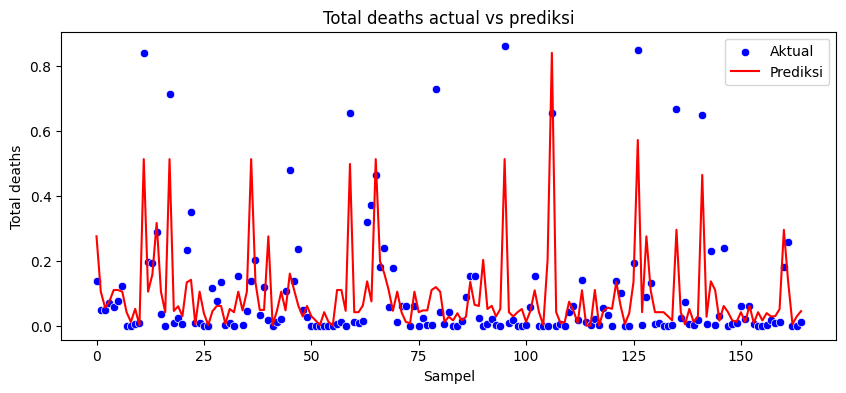

In [49]:
plt.figure(figsize=(10,4))
sns.scatterplot(x = range(len(y_test)), y = y_test, label = "Aktual", color = "blue")
sns.lineplot(x = range(len(y_pred)), y = y_pred, label = "Prediksi", color = "red")
plt.xlabel("Sampel")
plt.ylabel("Total deaths")
plt.title("Total deaths actual vs prediksi")
plt.legend()
plt.show()

In [50]:
score = knn.score(x_test,y_test)
score

0.633272646125455

KNN Classifier

In [51]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix

df = pd.read_csv("/Applications/MAMP/htdocs/local/kodingakademi/Python/bootcamp data analis/pertemuan/ML/penyakit_jantung.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,female,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,female,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,male,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,female,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,male,0,120,354,0,1,163,1,0.6,2,0,2,1


In [55]:
x = df.drop(columns=["target"])
y = df["target"]

x = pd.get_dummies(x, columns=["sex"])

scale = MinMaxScaler()
x.loc[:, "age" : "thal"].columns

Index(['age', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang',
       'oldpeak', 'slope', 'ca', 'thal'],
      dtype='object')

In [57]:
x[['age', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang',
       'oldpeak', 'slope', 'ca', 'thal']] = scale.fit_transform(x[['age', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang',
       'oldpeak', 'slope', 'ca', 'thal']])

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)

print(f"x_train = {len(x_train)}, x_test = {len(x_test)}")
print(f"y_train = {len(y_train)}, y_test = {len(y_test)}")

x_train = 212, x_test = 91
y_train = 212, y_test = 91


In [58]:
knn_classifier = KNeighborsClassifier()
knn_classifier.fit(x_train, y_train)

y_pred = knn_classifier.predict(x_test)
y_pred

array([0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0,
       1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1,
       1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0,
       1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1,
       1, 1, 1])

In [59]:
score = knn_classifier.score(x_test, y_test)
score

0.7802197802197802

In [60]:
cm = confusion_matrix(y_test, y_pred)
cm

array([[32,  9],
       [11, 39]])

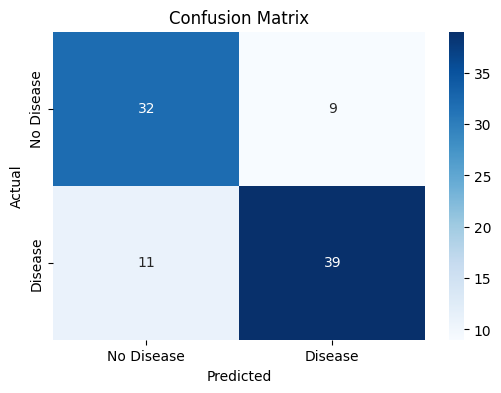

In [63]:
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Disease', 'Disease'], yticklabels=['No Disease', 'Disease'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

ASSIGNMENT

In [79]:
diabetes = pd.read_csv("/Applications/MAMP/htdocs/local/kodingakademi/Python/bootcamp data analis/pertemuan/ML/diabetes.csv")
diabetes

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Pedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [80]:
diabetes.isnull().sum()

Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
Pedigree         0
Age              0
Outcome          0
dtype: int64

In [81]:
diabetes.drop_duplicates(inplace= True)

In [82]:
x = diabetes.drop(columns=["Outcome"])
y = diabetes["Outcome"]

diabetes_scale = MinMaxScaler()
x.loc[:, "Pregnancies" : "Age"].columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'Pedigree', 'Age'],
      dtype='object')

In [83]:
x[['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'Pedigree', 'Age']] = diabetes_scale.fit_transform(x[['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'Pedigree', 'Age']])

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print(f"x_train = {len(x_train)}, x_test = {len(x_test)}")
print(f"y_train = {len(y_train)}, y_test = {len(y_test)}")

x_train = 614, x_test = 154
y_train = 614, y_test = 154


In [88]:
diabetes_model = KNeighborsClassifier()
diabetes_model.fit(x_train, y_train)

y_pred = diabetes_model.predict(x_test)
y_pred

array([0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0,
       0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0])

In [89]:
score = diabetes_model.score(x_test, y_test)
score

0.6883116883116883

In [90]:
cm = confusion_matrix(y_test, y_pred)
cm

array([[78, 21],
       [27, 28]])

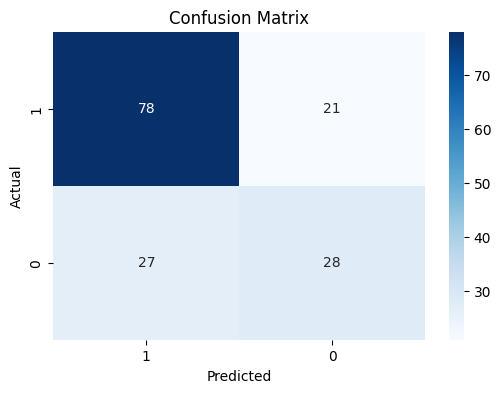

In [92]:
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['1', '0'], yticklabels=['1', '0'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()